# HW1 - Statistical and Machine Learning - CRETEL Théo
## 1. Data Generation

Cette section génère des jeux de données d’entraînement réalisables pour différentes tailles d’échantillons.
L’espace d’entrée est `X = [0, 1]`, et la fonction cible est un classifieur à seuil :
`f_theta(x) = 1 si x > theta, sinon 0`.
Chaque jeu de données est construit en échantillonnant des points uniformément dans `[0,1]` et en attribuant des étiquettes selon le seuil cible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt #pour generer le graphique


#fonction qui genere un dataset de taille m avec un seuil theta
def generate_dataset(m, theta=0.5, seed=None): #theta set à 0.5 par defaut pour un bon exemple visuel et symétrique (0.5 seprare l'intervalle [0,1] en deux parties égales)
    rng = np.random.default_rng(seed)
    x = rng.uniform(0.0, 1.0, size=m)
    y = (x > theta).astype(int)
    return x, y

sample_sizes = [5, 10, 20, 50, 100, 200]
theta = 0.5

for m in sample_sizes:
    x, y = generate_dataset(m, theta=theta, seed=100 + m)
    print(f'\nSample size m={m}:')
    print('x =', np.round(x, 3))
    print('y =', y)



Sample size m=5:
x = [0.638 0.991 0.097 0.507 0.396]
y = [1 1 0 1 0]

Sample size m=10:
x = [0.93  0.512 0.713 0.502 0.24  0.876 0.069 0.703 0.098 0.446]
y = [1 1 1 1 0 1 0 1 0 0]

Sample size m=20:
x = [0.854 0.057 0.251 0.654 0.578 0.563 0.543 0.373 0.979 0.645 0.033 0.472
 0.346 0.195 0.56  0.36  0.518 0.083 0.121 0.874]
y = [1 0 0 1 1 1 1 0 1 1 0 0 0 0 1 0 1 0 0 1]

Sample size m=50:
x = [0.005 0.931 0.785 0.334 0.686 0.732 0.825 0.107 0.309 0.313 0.594 0.611
 0.917 0.739 0.377 0.795 0.487 0.579 0.974 0.688 0.585 0.274 0.838 0.302
 0.173 0.802 0.344 0.438 0.153 0.276 0.564 0.865 0.083 0.975 0.923 0.407
 0.781 0.647 0.225 0.824 0.345 0.569 0.686 0.247 0.875 0.156 0.695 0.165
 0.481 0.522]
y = [0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 0 1 1 1 1 0 1 0 0 1 0 0 0 0 1 1 0 1 1 0 1
 1 0 1 0 1 1 0 1 0 1 0 0 1]

Sample size m=100:
x = [0.647 0.664 0.03  0.178 0.573 0.551 0.527 0.374 0.061 0.37  0.358 0.242
 0.044 0.909 0.527 0.114 0.141 0.447 0.501 0.785 0.041 0.272 0.85  0.92
 0.562 0.267 0.736 0.0

### Visualisation d’un jeu de données généré

On trace un jeu de données de taille `m = 20` pour visualiser la règle de seuil. Les points situés à gauche du seuil sont étiquetés `0`, tandis que ceux situés à droite sont étiquetés `1`.

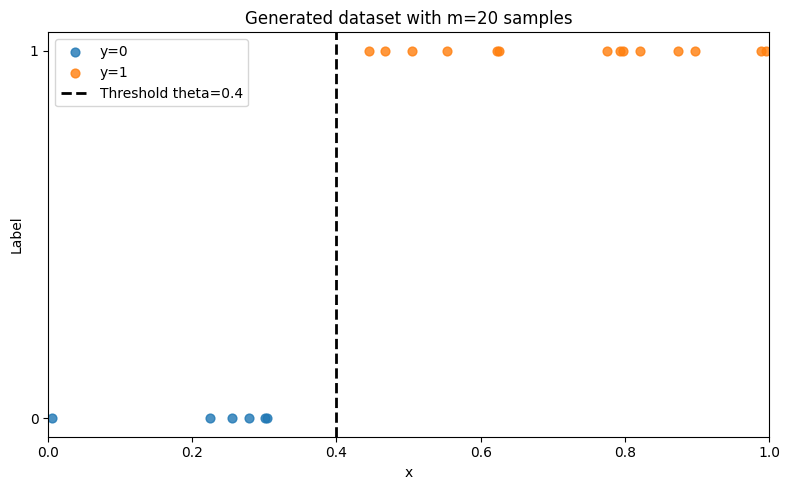

In [2]:
m_plot = 20
theta = 0.4 #exemple avec theta=0.4 pour montrer la séparation des classes dans le graphique
x, y = generate_dataset(m_plot, theta=theta, seed=7)

plt.figure(figsize=(8, 5))#fenetre pour le graphique
plt.scatter(x[y == 0], np.zeros(np.sum(y == 0)), color='tab:blue', label='y=0', s=40, alpha=0.8)# points dont le label est 0 (y=0) sont en bleu
plt.scatter(x[y == 1], np.ones(np.sum(y == 1)), color='tab:orange', label='y=1', s=40, alpha=0.8)# points dont le label est 1 (y=1) sont en orange
plt.axvline(theta, color='black', linestyle='--', linewidth=2, label=f'Threshold theta={theta}') #ligne verticale pour le seuil theta
plt.yticks([0, 1], ['0', '1'])#graduation de l'axe y pour montrer les classes
plt.xlabel('x')#axe x
plt.ylabel('Label')#axe y
plt.title(f'Generated dataset with m={m_plot} samples')
plt.xlim(0, 1)#limites de l'axe x (0,1) car les données sont générées dans cet intervalle
plt.legend()
plt.tight_layout()
plt.show()


### Interprétation

Les exemples d’entraînement sont générés uniformément dans l’espace des entrées. L’étiquette est déterminée par le fait que l’échantillon se trouve à droite ou à gauche du seuil `theta`. Comme la fonction cible est déterministe et parfaitement cohérente avec les étiquettes, ce jeu de données est dans le cadre réalisable.

## 2. Implémentation de l'ERM

L'algorithme de minimisation du risque empirique (ERM) consiste à choisir, parmi toutes les fonctions admissibles de la classe des seuils, celle qui minimise l'erreur sur le jeu d'apprentissage.

Pour une fonction de seuil h_t(x) = 1[x > t], on peut tester tous les seuils candidats possibles, calculer l'erreur empirique de chaque seuil, puis retenir le seuil avec l'erreur la plus faible.

Dans notre cas, les seuils candidats sont les milieux entre deux valeurs observées consécutives, ainsi que 0 et 1. Cette stratégie permet de parcourir toutes les séparations possibles entre classes et de trouver le meilleur seuil de façon simple et explicite.

La stratégie est donc ici : 1. Trier les valeurs de x et considérer des seuils candidats entre les valeurs consécutives.
2. Pour chaque seuil candidat, prédire les étiquettes avec la règle x > seuil.
3. Calculer l’erreur sur les données d’entraînement.
4. Garder le seuil qui donne l’erreur la plus faible.

Seuil estimé par ERM : theta_hat = 0.486
Erreur empirique : 0.000


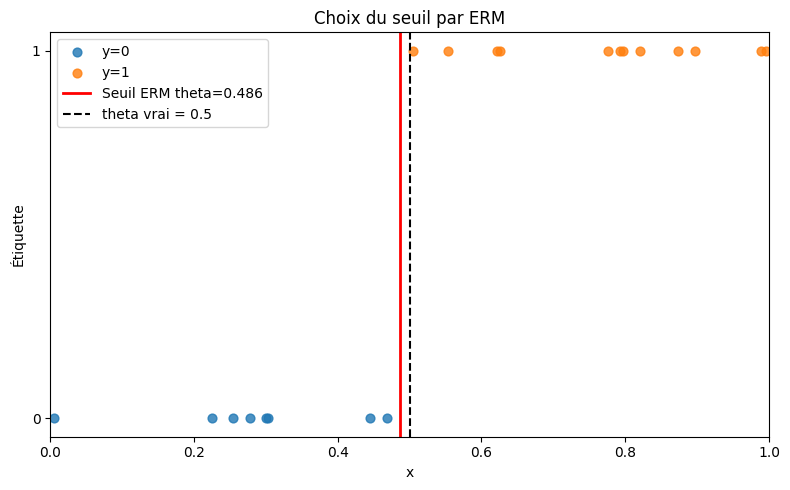

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def erm_threshold(x, y):
    #Renvoie le seuil optimal par ERM pour la classe des classifieurs à seuil.
    x = np.asarray(x, dtype=float)#les données d'entrée x sont converties en tableau numpy de type float
    y = np.asarray(y, dtype=int)#les étiquettes y sont converties en tableau numpy de type int
    x_unique = np.unique(x)#on récupère les valeurs uniques de x pour éviter les doublons

    if x_unique.size <= 1: #si toutes les valeurs de x sont identiques, on ne peut pas trouver un seuil optimal
        theta_opt = 0.5
        err_emp = np.mean(((x > theta_opt).astype(int) != y)) #calcul de l'erreur empirique pour le seuil choisi (ici 0.5)
        return theta_opt, err_emp 

    candidates = np.concatenate(([0.0], (x_unique[:-1] + x_unique[1:]) / 2, [1.0])) #liste des candidats pour le seuil : 0, les milieux entre les valeurs uniques de x, et 1
    best_theta = None
    best_error = np.inf #initialisation de l'erreur minimale à l'infini pour trouver le seuil optimal
    
    for theta in candidates: #on parcourt tous les candidats pour le seuil
        #en cas d'égalité, on conserve le premier seuil candidat
        #qui atteint l'erreur minimale (ici le plus petit seuil optimal)
        pred = (x > theta).astype(int)#predictions
        err = np.mean(pred != y)#erreur empirique 
        if err < best_error:#mise à jour du meilleur seuil et de la meilleure erreur 
            best_error = err
            best_theta = float(theta)

    return best_theta, best_error

x_train, y_train = generate_dataset(20, theta=0.5, seed=7) 
theta_hat, empirical_error = erm_threshold(x_train, y_train)#appel de la fonction 

print(f"Seuil estimé par ERM : theta_hat = {theta_hat:.3f}")
print(f"Erreur empirique : {empirical_error:.3f}")

#affichage du dataset et du seuil estimé par ERM
plt.figure(figsize=(8, 5))
plt.scatter(x_train[y_train == 0], np.zeros(np.sum(y_train == 0)), color='tab:blue', label='y=0', s=40, alpha=0.8)
plt.scatter(x_train[y_train == 1], np.ones(np.sum(y_train == 1)), color='tab:orange', label='y=1', s=40, alpha=0.8)
plt.axvline(theta_hat, color='red', linestyle='-', linewidth=2, label=f'Seuil ERM theta={theta_hat:.3f}')#le seuil estimé par ERM est affiché en rouge
plt.axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='theta vrai = 0.5')
plt.yticks([0, 1], ['0', '1'])
plt.xlabel('x')
plt.ylabel('Étiquette')
plt.title('Choix du seuil par ERM')
plt.xlim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### Interprétation

Sur cet exemple (`m = 20`, `theta = 0.5`), l'ERM trouve `theta_hat = 0.486` avec une erreur empirique nulle : il sépare parfaitement les exemples d'entraînement. Pourtant `theta_hat` n'est pas égal à `theta`. Tout seuil situé entre le plus grand point d'étiquette 0 et le plus petit point d'étiquette 1 est consistant avec l'échantillon, et l'ERM ne peut pas choisir le « bon » seuil parmi eux. Sous la loi uniforme, le risque réel du classifieur appris vaut `|theta_hat - theta| = 0.014` : petit mais non nul. Avec plus d'exemples, l'intervalle des seuils consistants se resserre autour de `theta`.

## 3. Évaluation des performances

Pour chaque taille d’entraînement `m`, on entraîne le classifieur ERM puis on mesure deux erreurs. L’erreur empirique est calculée sur les exemples d’entraînement. L’erreur de test est calculée sur un grand jeu de test indépendant de 10 000 exemples, généré avec le même seuil cible `theta = 0.5`. Cette erreur de test fournit une estimation du risque réel `L(h)`.

On compare ensuite les deux erreurs dans un tableau et sur un graphique. Les données sont ici dans le cadre réalisable : leurs étiquettes suivent toutes la même règle de seuil, sans bruit.

    m    theta_hat     Erreur empirique     Erreur de test
    5        0.463               0.0000             0.0333
   10        0.473               0.0000             0.0272
   20        0.516               0.0000             0.0153
   50        0.532               0.0000             0.0301
  100        0.513               0.0000             0.0130
  200        0.500               0.0000             0.0006


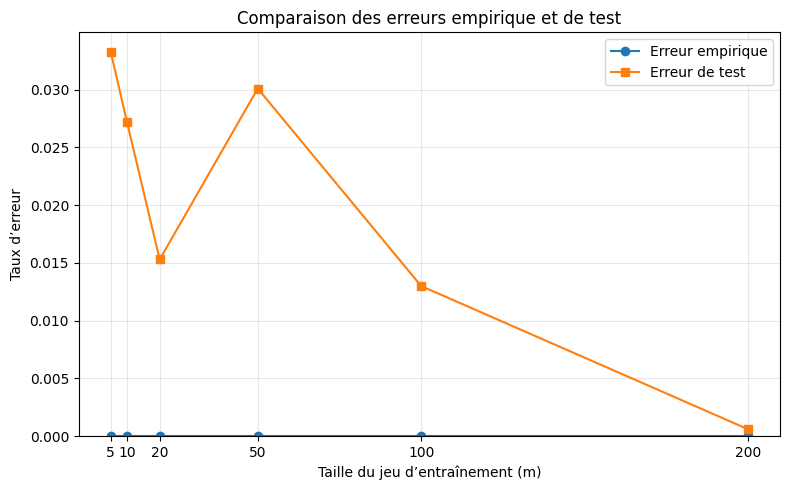

In [4]:
# Paramètres de l'évaluation
sample_sizes_eval = [5, 10, 20, 50, 100, 200]
theta_eval = 0.5
test_size_eval = 10_000

results_eval = []

for m_eval in sample_sizes_eval:
    # Générer un jeu d'entraînement, puis apprendre le seuil par ERM
    x_train_eval, y_train_eval = generate_dataset(
        m_eval, theta=theta_eval, seed=1000 + m_eval
    )
    theta_hat_eval, empirical_error_eval = erm_threshold(
        x_train_eval, y_train_eval
    )#la fonction erm_threshold est utilisée pour trouver le seuil optimal et l'erreur empirique sur le jeu d'entraînement

    # Le jeu de test est indépendant du jeu d'entraînement
    x_test_eval, y_test_eval = generate_dataset(
        test_size_eval, theta=theta_eval, seed=2000 + m_eval
    )
    y_pred_test_eval = (x_test_eval > theta_hat_eval).astype(int)
    test_error_eval = np.mean(y_pred_test_eval != y_test_eval)#calcul de l'erreur de test en comparant les prédictions avec les étiquettes réelles du jeu de test

    results_eval.append(
        (m_eval, theta_hat_eval, empirical_error_eval, test_error_eval)
    )

# Afficher les erreurs obtenues pour chaque taille d'entraînement
print(f"{'m':>5} {'theta_hat':>12} {'Erreur empirique':>20} {'Erreur de test':>18}")
for m_eval, theta_hat_eval, empirical_error_eval, test_error_eval in results_eval:
    print(
        f"{m_eval:5d} {theta_hat_eval:12.3f} "
        f"{empirical_error_eval:20.4f} {test_error_eval:18.4f}"
    )

# Comparer graphiquement l'erreur d'entraînement et l'erreur de test
m_values_eval = [result[0] for result in results_eval]
empirical_errors_eval = [result[2] for result in results_eval]
test_errors_eval = [result[3] for result in results_eval]

plt.figure(figsize=(8, 5))
plt.plot(m_values_eval, empirical_errors_eval, marker='o', label='Erreur empirique')
plt.plot(m_values_eval, test_errors_eval, marker='s', label='Erreur de test')
plt.xlabel('Taille du jeu d’entraînement (m)')
plt.ylabel('Taux d’erreur')
plt.title('Comparaison des erreurs empirique et de test')
plt.xticks(m_values_eval)
plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Interprétation

Dans le cadre réalisable, l’ERM peut obtenir une erreur empirique nulle, car les exemples d’entraînement sont séparables par un seuil. L’erreur de test peut néanmoins être positive : le seuil appris n’est pas nécessairement exactement égal au seuil cible. En général, davantage d’exemples d’entraînement aide à estimer le seuil et à réduire l’erreur de test. La diminution n’est toutefois pas nécessairement monotone pour une seule réalisation aléatoire. Enfin, l’erreur de test affichée est une estimation calculée sur 10 000 exemples, et non la valeur exacte du risque.

## 4. Vérification expérimentale de l’apprentissage PAC

On fixe une précision `epsilon = 0.1` et une confiance cible `1 - delta = 0.95` (`delta = 0.05`). Pour chaque taille d’entraînement, on répète l’expérience 1 000 fois avec des échantillons indépendants. À chaque répétition, on entraîne un seuil avec l’ERM puis on vérifie si son risque réel dépasse `epsilon`.

Comme les entrées suivent la loi uniforme sur `[0, 1]`, le risque réel d’un seuil `theta_hat` par rapport au seuil cible `theta` est exactement `abs(theta_hat - theta)` : les deux classifieurs ne sont en désaccord que sur l’intervalle entre leurs seuils. La fréquence observée des répétitions où `L(h) > epsilon` estime donc directement `Pr(L(h) > epsilon)`, sans erreur supplémentaire due à un jeu de test fini. La ligne horizontale `delta` sert de repère pour la probabilité d’échec visée.

epsilon = 0.1, delta = 0.05, répétitions = 1000
    m     Échecs     Pr(L(h) > epsilon) estimée
    5        327                         0.3270
   10         90                         0.0900
   20         10                         0.0100
   50          0                         0.0000
  100          0                         0.0000
  200          0                         0.0000


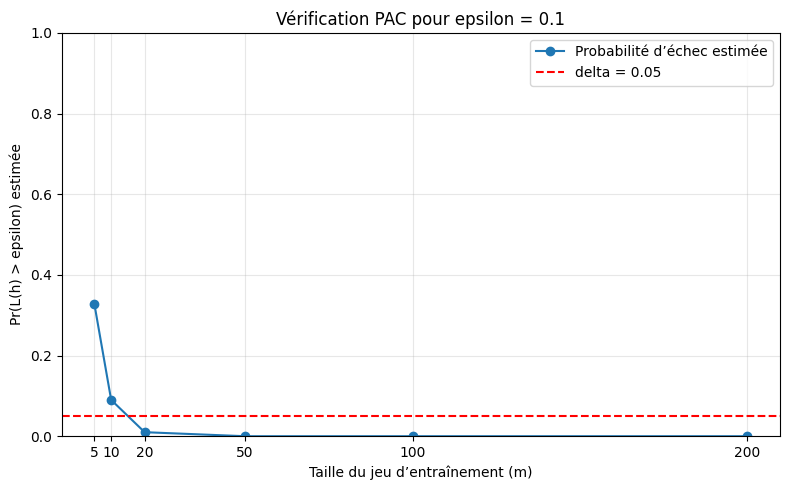

In [5]:
# Paramètres de l'expérience PAC (cadre réalisable)
sample_sizes_pac = [5, 10, 20, 50, 100, 200]
epsilon_pac = 0.1
delta_pac = 0.05 #ce choix de delta est arbitraire et peut être ajusté selon les besoins de l'expérience
n_repetitions_pac = 1000
theta_pac = 0.5

pac_results = []

for m_pac in sample_sizes_pac:
    failures_pac = 0#compteur pour le nombre d'échecs (où l'erreur réelle dépasse epsilon)

    for repetition_pac in range(n_repetitions_pac):
        # Chaque répétition utilise un jeu d'entraînement indépendant
        seed_pac = 400000 + 1000 * m_pac + repetition_pac #création d'une seed unique pour chaque répétition afin de garantir l'indépendance des jeux d'entraînement
        x_train_pac, y_train_pac = generate_dataset(
            m_pac, theta=theta_pac, seed=seed_pac
        )
        theta_hat_pac, _ = erm_threshold(x_train_pac, y_train_pac)#fonction pour seuil optimal par ERM

        # Pour X uniforme sur [0, 1], le risque exact est la distance entre les seuils
        true_error_pac = abs(theta_hat_pac - theta_pac)
        if true_error_pac > epsilon_pac:
            failures_pac += 1 

    failure_probability_pac = failures_pac / n_repetitions_pac
    pac_results.append((m_pac, failure_probability_pac, failures_pac))

# Afficher la probabilité d'échec estimée pour chaque taille m
print(f"epsilon = {epsilon_pac}, delta = {delta_pac}, répétitions = {n_repetitions_pac}")
print(f"{'m':>5} {'Échecs':>10} {'Pr(L(h) > epsilon) estimée':>30}")
for m_pac, probability_pac, failures_pac in pac_results:
    print(f"{m_pac:5d} {failures_pac:10d} {probability_pac:30.4f}")

# Tracer l'évolution de la probabilité d'échec avec la taille d'entraînement
m_values_pac = [result[0] for result in pac_results]
failure_probabilities_pac = [result[1] for result in pac_results]

plt.figure(figsize=(8, 5))
plt.plot(m_values_pac, failure_probabilities_pac, marker='o', label='Probabilité d’échec estimée')
plt.axhline(delta_pac, color='red', linestyle='--', label=f'delta = {delta_pac}')
plt.xlabel('Taille du jeu d’entraînement (m)')
plt.ylabel('Pr(L(h) > epsilon) estimée')
plt.title(f"Vérification PAC pour epsilon = {epsilon_pac}")
plt.xticks(m_values_pac)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Interprétation

La probabilité affichée estime la fréquence à laquelle le seuil appris a un risque réel supérieur à `epsilon = 0.1`. Dans cette expérience, les estimations obtenues pour `m = 5, 10, 20, 50, 100, 200` sont respectivement `0.327`, `0.090`, `0.010`, `0.000`, `0.000` et `0.000`. Elles diminuent lorsque `m` augmente, ce qui illustre l’amélioration de la généralisation avec davantage d’exemples. La ligne `delta = 0.05` représente la probabilité d’échec visée pour la confiance choisie : l’estimation passe sous cette ligne à partir de `m = 20` dans cette expérience. Une estimation égale à zéro pour les grandes tailles signifie qu’aucun échec n’a été observé parmi les 1 000 répétitions ; cela ne prouve pas que la probabilité réelle est exactement nulle.

## 5. Du PAC au PAC agnostique

On reprend les expériences précédentes en ajoutant un bruit d’étiquette indépendant : chaque étiquette est inversée avec une probabilité `eta = 0.1`. Le seuil cible reste `theta = 0.5`, et on conserve les mêmes tailles d’entraînement, le même `epsilon = 0.1` et 1 000 répétitions pour pouvoir comparer les expériences.

Pour l’évaluation des performances, on calcule l’erreur empirique sur les exemples bruités d’entraînement et l’erreur de test sur un jeu indépendant dont les étiquettes sont également bruitées. Pour estimer la probabilité d’échec sur les répétitions, on utilise le risque réel exact. Avec un bruit de taux `eta`, le meilleur seuil possible a un risque irréductible `L* = eta`. Pour le seuil appris `theta_hat`, `L(h) = eta + (1 - 2 eta) |theta_hat - theta|`; on mesure l’événement PAC agnostique Pr(L(h) - L* > epsilon).

Taux de bruit eta = 0.1 ; jeu de test = 10000 exemples
    m    theta_hat     Erreur empirique     Erreur de test
    5        0.644               0.0000             0.2161
   10        0.520               0.0000             0.1099
   20        0.543               0.0500             0.1332
   50        0.498               0.0800             0.1051
  100        0.498               0.1400             0.1056
  200        0.502               0.1050             0.0957

Résultats moyens sur 1000 répétitions (L* = eta = 0.1)
    m   Erreur empirique moyenne    Risque réel moyen     Pr(L-L*>epsilon)
    5                     0.0546               0.2161               0.3800
   10                     0.0796               0.1746               0.2350
   20                     0.0896               0.1384               0.0930
   50                     0.0936               0.1158               0.0090
  100                     0.0976               0.1078               0.0000
  200                     

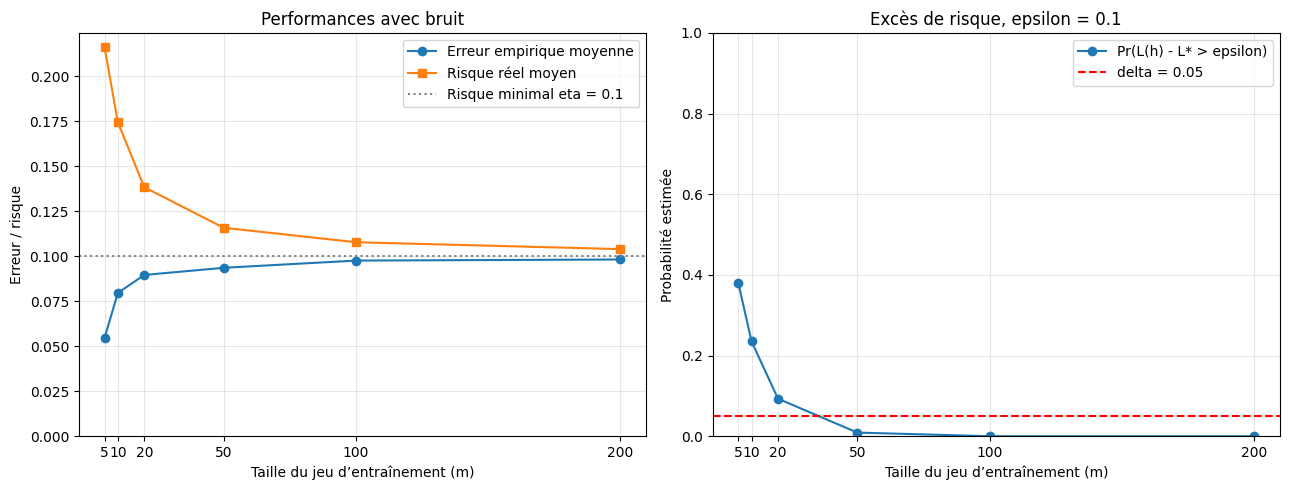

In [6]:
# Paramètres de l'expérience agnostique
eta_agnostic = 0.1
theta_agnostic = 0.5
sample_sizes_agnostic = [5, 10, 20, 50, 100, 200]
test_size_agnostic = 10_000
n_repetitions_agnostic = 1000
epsilon_agnostic = 0.1

def add_label_noise(y, eta, seed): #bruit: inversion indépendante de chaque étiquette avec probabilité eta
    rng_noise = np.random.default_rng(seed)
    flip = rng_noise.random(len(y)) < eta
    return np.logical_xor(y, flip).astype(int)

#evaluation empirique et test, avec un jeu de test indépendant pour chaque m
agnostic_performance = []
for m_agnostic in sample_sizes_agnostic: #pour chaque taille d'échantillon, on génère un jeu d'entraînement et un jeu de test indépendants
    x_train_agnostic, y_clean_train_agnostic = generate_dataset(
        m_agnostic, theta=theta_agnostic, seed=500000 + m_agnostic
    )
    y_train_agnostic = add_label_noise(
        y_clean_train_agnostic, eta_agnostic, seed=510000 + m_agnostic
    )
    theta_hat_agnostic, empirical_error_agnostic = erm_threshold(
        x_train_agnostic, y_train_agnostic
    )

    x_test_agnostic, y_clean_test_agnostic = generate_dataset(
        test_size_agnostic, theta=theta_agnostic, seed=520000 + m_agnostic
    )
    y_test_agnostic = add_label_noise(
        y_clean_test_agnostic, eta_agnostic, seed=530000 + m_agnostic
    )
    y_pred_test_agnostic = (x_test_agnostic > theta_hat_agnostic).astype(int)
    test_error_agnostic = np.mean(y_pred_test_agnostic != y_test_agnostic)
    agnostic_performance.append(
        (m_agnostic, empirical_error_agnostic, test_error_agnostic, theta_hat_agnostic)
    )

print(f"Taux de bruit eta = {eta_agnostic} ; jeu de test = {test_size_agnostic} exemples") #taux de bruit et taille du jeu de test 
print(f"{'m':>5} {'theta_hat':>12} {'Erreur empirique':>20} {'Erreur de test':>18}")
for m_agnostic, emp_err, test_err, theta_hat in agnostic_performance: #pour chaque taille d'échantillon, on affiche le seuil estimé, l'erreur empirique et l'erreur de test
    print(f"{m_agnostic:5d} {theta_hat:12.3f} {emp_err:20.4f} {test_err:18.4f}")

#répéter l'expérience afin d'estimer les probabilités d'échec
agnostic_results = []#tableau pour stocker les résultats de l'expérience agnostique
for m_agnostic in sample_sizes_agnostic:
    failures_excess = 0
    empirical_errors_repeated = []
    true_errors_repeated = []

    for repetition_agnostic in range(n_repetitions_agnostic):#pour chaque répétition, on génère un jeu d'entraînement indépendant et on calcule le seuil optimal par ERM
        seed_base = 600000 + 1000 * m_agnostic + repetition_agnostic
        x_train_rep, y_clean_rep = generate_dataset(
            m_agnostic, theta=theta_agnostic, seed=seed_base
        )
        y_train_rep = add_label_noise(y_clean_rep, eta_agnostic, seed=seed_base + 500000)
        theta_hat_rep, empirical_error_rep = erm_threshold(x_train_rep, y_train_rep)

        # Risque réel et excès de risque calculés exactement sous la loi uniforme
        true_error_rep = eta_agnostic + (1 - 2 * eta_agnostic) * abs(
            theta_hat_rep - theta_agnostic
        )
        excess_risk_rep = true_error_rep - eta_agnostic
        empirical_errors_repeated.append(empirical_error_rep)
        true_errors_repeated.append(true_error_rep)
        failures_excess += excess_risk_rep > epsilon_agnostic

    agnostic_results.append(
        (
            m_agnostic,
            np.mean(empirical_errors_repeated),
            np.mean(true_errors_repeated),
            failures_excess / n_repetitions_agnostic,
        )
    )

print(f"\nRésultats moyens sur {n_repetitions_agnostic} répétitions (L* = eta = {eta_agnostic})")
print(f"{'m':>5} {'Erreur empirique moyenne':>26} {'Risque réel moyen':>20} {'Pr(L-L*>epsilon)':>20}")
for m_agnostic, mean_emp, mean_true, prob_excess in agnostic_results:
    print(f"{m_agnostic:5d} {mean_emp:26.4f} {mean_true:20.4f} {prob_excess:20.4f}")

#comparer le risque et la probabilité d'excès de risque lorsque m augmente
m_values_agnostic = [result[0] for result in agnostic_results]
mean_empirical_agnostic = [result[1] for result in agnostic_results]
mean_true_agnostic = [result[2] for result in agnostic_results]
excess_failure_probabilities = [result[3] for result in agnostic_results]

#affichage des résultats dans deux sous-graphes : l'un pour les erreurs et l'autre pour les probabilités d'échec
fig, axes = plt.subplots(1, 2, figsize=(13, 5)) #taille de la figure pour les deux sous-graphes
axes[0].plot(m_values_agnostic, mean_empirical_agnostic, marker='o', label='Erreur empirique moyenne')
axes[0].plot(m_values_agnostic, mean_true_agnostic, marker='s', label='Risque réel moyen')
axes[0].axhline(eta_agnostic, color='gray', linestyle=':', label=f'Risque minimal eta = {eta_agnostic}')
axes[0].set_xlabel('Taille du jeu d’entraînement (m)')
axes[0].set_ylabel('Erreur / risque')
axes[0].set_title('Performances avec bruit')
axes[0].set_xticks(m_values_agnostic)
axes[0].set_ylim(bottom=0)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(m_values_agnostic, excess_failure_probabilities, marker='o', label='Pr(L(h) - L* > epsilon)')
axes[1].axhline(delta_pac, color='red', linestyle='--', label=f'delta = {delta_pac}')
axes[1].set_xlabel('Taille du jeu d’entraînement (m)')
axes[1].set_ylabel('Probabilité estimée')
axes[1].set_title(f"Excès de risque, epsilon = {epsilon_agnostic}")
axes[1].set_xticks(m_values_agnostic)
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

### Interprétation et comparaison PAC / PAC agnostique

**Erreur empirique avec bruit.** Contrairement au cadre réalisable, l'erreur empirique ne reste pas nulle en général : sur les 1 000 répétitions, sa moyenne vaut `0.055` pour `m = 5`, `0.080` pour `m = 10`, `0.090` pour `m = 20`, `0.094` pour `m = 50`, `0.098` pour `m = 100` et `0.098` pour `m = 200`. Elle reste inférieure à `eta = 0.1` et s'en rapproche par le bas quand `m` augmente. Cela s'explique par l'optimisme de l'ERM : le seuil est choisi précisément pour minimiser les erreurs sur l'échantillon d'entraînement, il s'ajuste donc en partie au bruit et sous-estime l'erreur réelle. Ce biais diminue avec `m`, car il devient plus difficile de s'ajuster au bruit sur un grand échantillon. L'erreur empirique peut donc encore être nulle sur un très petit échantillon par hasard (comme pour `m = 5` et `m = 10` dans le tableau de performance), mais pas de façon systématique.

**Risque réel et excès de risque.** Le risque réel moyen diminue de `0.2161` pour `m = 5` à `0.1040` pour `m = 200`, en se rapprochant de la limite théorique `L* = eta = 0.1`. Contrairement au cadre réalisable, le risque total ne peut pas tendre vers zéro en présence de bruit ; c'est l'excès de risque `L(h) - L*` qui peut tendre vers zéro. L'erreur empirique moyenne reste inférieure au risque réel moyen, car l'ERM minimise les erreurs sur les données d'entraînement et peut s'adapter en partie au bruit de l'échantillon.

**Probabilité d'échec.** La probabilité estimée que l'excès de risque dépasse `epsilon = 0.1` passe de `0.380` pour `m = 5` à `0.009` pour `m = 50`, puis à `0` observé pour `m = 100` et `m = 200`. Cela montre que l'augmentation de la taille d'entraînement améliore également la généralisation dans le cadre agnostique. Une fréquence observée nulle signifie toutefois qu'aucun échec n'a été rencontré parmi les 1 000 répétitions, et non que la probabilité théorique est nécessairement nulle.

PAC : Pr(L(h) > epsilon) ; PAC agnostique : Pr(L(h) - L* > epsilon).
    m     PAC: Pr(L>epsilon)     Agnostique: Pr(L-L*>epsilon)
    5                 0.3270                           0.3800
   10                 0.0900                           0.2350
   20                 0.0100                           0.0930
   50                 0.0000                           0.0090
  100                 0.0000                           0.0000
  200                 0.0000                           0.0000


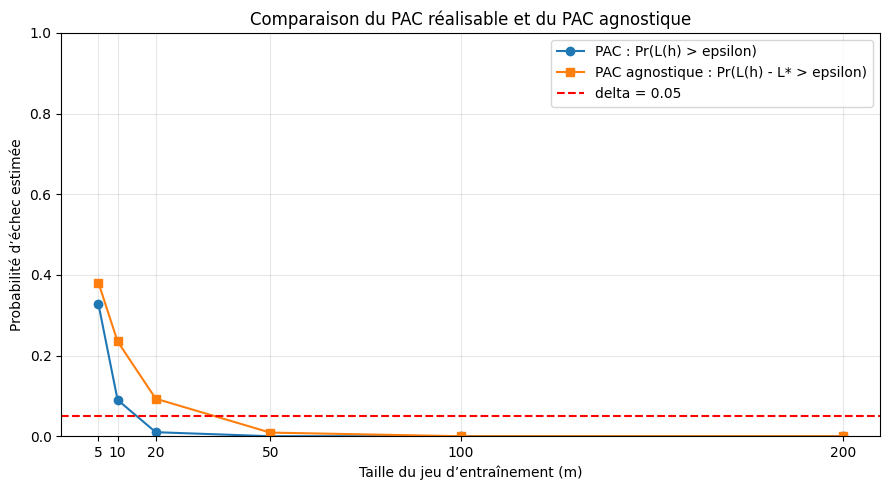

In [7]:
# Comparer les résultats des expériences PAC et PAC agnostique
pac_probabilities_by_m = {
    m: probability for m, probability, _ in pac_results
}
agnostic_results_by_m = {
    result[0]: result for result in agnostic_results
}

common_sample_sizes = sorted(
    set(pac_probabilities_by_m) & set(agnostic_results_by_m)
)
if not common_sample_sizes:
    raise ValueError('Aucune taille m commune aux expériences PAC et agnostique.')

pac_failure_comparison = [pac_probabilities_by_m[m] for m in common_sample_sizes]
agnostic_excess_failure = [agnostic_results_by_m[m][3] for m in common_sample_sizes]

print('PAC : Pr(L(h) > epsilon) ; PAC agnostique : Pr(L(h) - L* > epsilon).')
print(f"{'m':>5} {'PAC: Pr(L>epsilon)':>22} {'Agnostique: Pr(L-L*>epsilon)':>32}")
for index, m in enumerate(common_sample_sizes):
    print(
        f"{m:5d} {pac_failure_comparison[index]:22.4f} "
        f"{agnostic_excess_failure[index]:32.4f}"
    )

# Comparaison des probabilités d'échec PAC et de l'excès de risque agnostique
plt.figure(figsize=(9, 5))
plt.plot(
    common_sample_sizes,
    pac_failure_comparison,
    marker='o',
    label='PAC : Pr(L(h) > epsilon)',
)
plt.plot(
    common_sample_sizes,
    agnostic_excess_failure,
    marker='s',
    label='PAC agnostique : Pr(L(h) - L* > epsilon)',
)
plt.axhline(delta_pac, color='red', linestyle='--', label=f'delta = {delta_pac}')
plt.xlabel('Taille du jeu d’entraînement (m)')
plt.ylabel('Probabilité d’échec estimée')
plt.title('Comparaison du PAC réalisable et du PAC agnostique')
plt.xticks(common_sample_sizes)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Conclusion : PAC contre PAC agnostique

Dans les deux cadres, la probabilité que l’erreur dépasse la précision choisie diminue lorsque la taille d’entraînement augmente : l’apprentissage se généralise donc mieux avec davantage d’exemples. Dans les résultats obtenus, la probabilité d’échec PAC passe de `0.327` pour `m = 5` à `0` observé dès `m = 50`. En PAC agnostique, la probabilité que l’excès de risque dépasse `epsilon` passe de `0.380` à `0.009` pour `m = 50`, puis à `0` observé pour `m = 100` et `m = 200`.

La différence essentielle est le niveau d’erreur visé : dans le cadre PAC réalisable, les données suivent exactement la règle cible et le risque peut tendre vers zéro. Dans le cadre agnostique, les étiquettes sont bruitées : même le meilleur classifieur de la classe a un risque minimal `L* = eta = 0.1`. On évalue donc l’apprentissage agnostique par son excès de risque `L(h) - L*`, qui peut tendre vers zéro, plutôt que d’exiger que le risque total s’annule. Les zéros observés sont des fréquences nulles parmi 1 000 répétitions, et ne prouvent pas que la probabilité théorique soit exactement nulle.

**Vitesse de convergence.** Les deux probabilités d'échec diminuent avec `m`, mais pas à la même vitesse : l'apprentissage agnostique est plus lent. Pour `m = 10`, la probabilité d'échec est de `0.090` en PAC contre `0.235` en agnostique ; pour `m = 20`, `0.010` contre `0.093` ; pour `m = 50`, `0.000` contre `0.009`. Il faut donc davantage d'exemples en présence de bruit pour atteindre la même confiance `1 - delta`. Avec `delta = 0.05`, la barre est franchie dès `m = 20` en PAC, mais seulement entre `m = 20` et `m = 50` en agnostique. Cela correspond au cours : la complexité d'échantillon est de l'ordre de `1/epsilon` dans le cas réalisable, mais de l'ordre de `1/epsilon²` dans le cas agnostique, car il faut estimer le meilleur seuil à travers le bruit des étiquettes.